Cluade-Sonnet-5-5-Medium 작성

# MNIST RNN: 28줄을 한 줄씩 읽는 과정 시각화

이미지 한 장(28×28)을 **28스텝짜리 시퀀스**로 보고, 스텝마다 은닉 상태 `h_t`(64칸 메모)가 어떻게 바뀌는지 직접 확인합니다.

- 입력 `X`: `(Batch, 28, 28)` = (배치, 타임스텝=행, 한 행의 픽셀 수)
- 스텝마다 `(Batch, 28) → (Batch, 64)`
- 마지막 `h_27` → `Linear(64, 10)` → 클래스 점수(logits)

**준비물**: `torch`, `torchvision`, `matplotlib`, `numpy` (슬라이더는 `ipywidgets`가 있으면 사용, 없으면 정적 그림으로 대체)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. 모델 정의 (질문에 주신 코드 그대로)

In [2]:
class MNIST10ClassRNN(nn.Module):
    def __init__(self, image_width=28, hidden_dim=64, num_classes=10):
        super().__init__()
        self.rnn = nn.RNN(input_size=image_width, hidden_size=hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        outputs, h_n = self.rnn(x)           # outputs: (배치, 28스텝, 64), h_n: (1, 배치, 64)
        logits = self.fc(h_n.squeeze(0))     # 마지막 스텝 h_27로 0~9 분류
        return logits, outputs

model = MNIST10ClassRNN(image_width=28, hidden_dim=64, num_classes=10).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
criterion = nn.CrossEntropyLoss()

## 2. 데이터 로드 및 (선택) 짧은 학습

`TRAIN = False`로 두면 **학습 전(랜덤 가중치)** 상태를 보고, `True`면 1에폭 학습한 뒤 보게 됩니다.
학습 후에는 마지막 스텝의 점수가 정답 숫자 쪽으로 높아지는 것을 볼 수 있습니다.

In [3]:
TRAIN = True      # False: 학습 전 가중치로 시각화
EPOCHS = 1

tfm = transforms.ToTensor()   # (1, 28, 28), 값 0~1
train_ds = datasets.MNIST("./data", train=True,  download=True, transform=tfm)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=tfm)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=1000)

if TRAIN:
    for ep in range(EPOCHS):
        model.train()
        for i, (xb, yb) in enumerate(train_loader):
            xb = xb.squeeze(1).to(device)      # (B,1,28,28) -> (B,28,28)
            yb = yb.to(device)
            logits, _ = model(xb)
            loss = criterion(logits, yb)
            optimizer.zero_grad()
            loss.backward()                    # 28스텝을 거슬러 올라가는 BPTT
            optimizer.step()
            if i % 100 == 0:
                print(f"epoch {ep+1} step {i:3d}  loss {loss.item():.4f}")

    model.eval()
    correct = 0
    with torch.no_grad():
        for xb, yb in test_loader:
            logits, _ = model(xb.squeeze(1).to(device))
            correct += (logits.argmax(1).cpu() == yb).sum().item()
    print(f"test acc: {correct / len(test_ds):.4f}")

epoch 1 step   0  loss 2.2961
epoch 1 step 100  loss 1.2849
epoch 1 step 200  loss 1.0285
epoch 1 step 300  loss 0.9922
epoch 1 step 400  loss 0.7327
test acc: 0.8044


## 3. 샘플 한 장을 넣어 shape 확인

In [4]:
SAMPLE_IDX = 0   # 보고 싶은 테스트 이미지 번호 (바꿔서 다시 실행해 보세요)

model.eval()
img, label = test_ds[SAMPLE_IDX]
x = img.squeeze(0).unsqueeze(0).to(device)          # (1, 28, 28)  -> Batch=1

with torch.no_grad():
    logits, outputs = model(x)

print("Input X     :", tuple(x.shape),       "  (Batch, 28스텝, 28픽셀)")
print("outputs     :", tuple(outputs.shape), " (Batch, 28스텝, 64뉴런) = h_0 ... h_27")
print("logits      :", tuple(logits.shape),  "      (Batch, 10)")
print("정답 라벨   :", label, "| 모델 예측:", logits.argmax(1).item())

# 시각화용 numpy 변환
IMG    = x[0].cpu().numpy()          # (28, 28)
H      = outputs[0].cpu().numpy()    # (28, 64)   각 행 = h_t
LOGITS = logits[0].cpu().numpy()     # (10,)

Input X     : (1, 28, 28)   (Batch, 28스텝, 28픽셀)
outputs     : (1, 28, 64)  (Batch, 28스텝, 64뉴런) = h_0 ... h_27
logits      : (1, 10)       (Batch, 10)
정답 라벨   : 7 | 모델 예측: 7


## 4. 직접 계산한 `h_t`가 `nn.RNN` 출력과 같은지 확인

`h_t = tanh(W_x · x_t + W_h · h_{t-1} + b)` 를 for문으로 풀어서 비교합니다.
(PyTorch는 편향이 `b_ih`, `b_hh` 두 개라서 둘을 더한 것이 설명 속 `b`입니다.)

In [5]:
rnn = model.rnn
W_x, W_h = rnn.weight_ih_l0, rnn.weight_hh_l0     # (64, 28), (64, 64)
b = rnn.bias_ih_l0 + rnn.bias_hh_l0               # (64,)

h = torch.zeros(1, 64, device=device)             # h_{-1} = 0
manual = []
with torch.no_grad():
    for t in range(28):
        h = torch.tanh(x[:, t, :] @ W_x.T + h @ W_h.T + b)   # (1,28)->(1,64)
        manual.append(h)
manual = torch.stack(manual, dim=1)               # (1, 28, 64)

print("직접 계산 == nn.RNN outputs :", torch.allclose(manual, outputs, atol=1e-5))
print("W_x shape:", tuple(W_x.shape), "| W_h shape:", tuple(W_h.shape), "(모든 스텝에서 재사용)")

# 마지막 스텝 h_27이 h_n과 같은지, fc를 거친 값이 logits와 같은지
with torch.no_grad():
    _, h_n = rnn(x)
print("outputs[:, -1] == h_n       :", torch.allclose(outputs[:, -1], h_n.squeeze(0)))
print("fc(h_27) == logits          :", torch.allclose(model.fc(outputs[:, -1]), logits, atol=1e-6))

직접 계산 == nn.RNN outputs : False
W_x shape: (64, 28) | W_h shape: (64, 64) (모든 스텝에서 재사용)
outputs[:, -1] == h_n       : True
fc(h_27) == logits          : True


## 5. 한 스텝을 그리는 함수

- 왼쪽 위: 이미지와 **지금 읽는 줄**(빨간 테두리). 아직 안 읽은 줄은 흐리게
- 가운데 위: `h_t`를 8×8 격자로 (빨강 양수, 파랑 음수)
- 오른쪽 위: 지금까지의 메모 기록 `h_0 ... h_t` (세로=스텝, 가로=64뉴런)
- 왼쪽 아래: 지금 줄 `x_t`의 28픽셀
- 오른쪽 아래: 마지막 스텝(27)에서만 10개 클래스 점수가 나타남

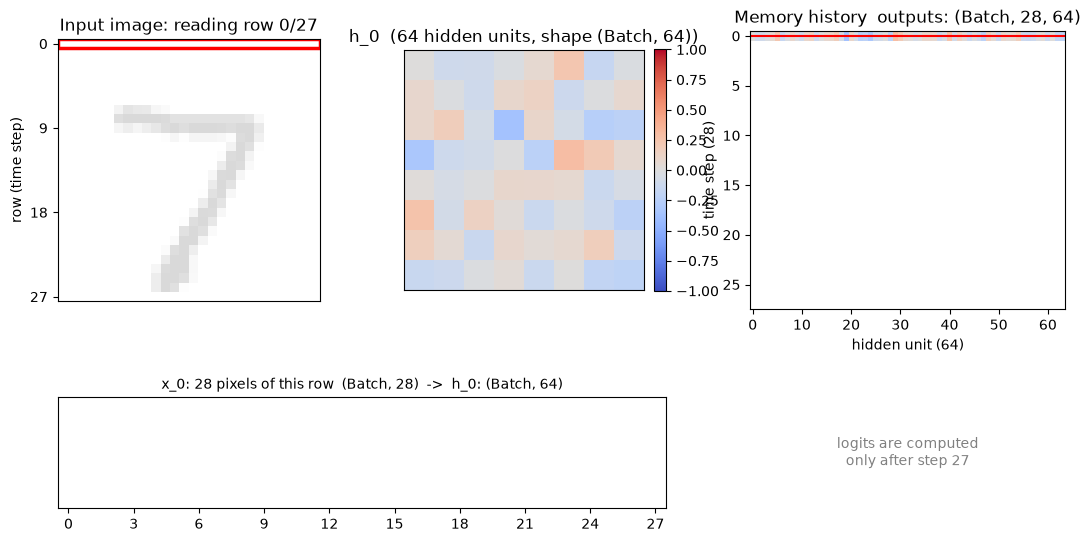

In [6]:
def draw_step(t, img=None, H=None, logits=None, label=None, fig=None):
    img    = IMG if img is None else img
    H      = H if H is not None else globals()["H"]
    logits = LOGITS if logits is None else logits

    if fig is None:
        fig = plt.figure(figsize=(13, 6.2))
    fig.clf()
    gs = fig.add_gridspec(2, 3, height_ratios=[3, 1.2], width_ratios=[1, 1, 1.2], hspace=0.45, wspace=0.3)

    # (1) 이미지 + 현재 줄 하이라이트
    ax = fig.add_subplot(gs[0, 0])
    shown = img.copy()
    shown[t + 1:, :] *= 0.15                          # 아직 안 읽은 줄은 흐리게
    ax.imshow(shown, cmap="gray_r", vmin=0, vmax=1)
    ax.add_patch(plt.Rectangle((-0.5, t - 0.5), 28, 1, fill=False, ec="red", lw=2.5))
    ax.set_title(f"Input image: reading row {t}/27")
    ax.set_xticks([]); ax.set_yticks(range(0, 28, 9)); ax.set_ylabel("row (time step)")

    # (2) h_t 8x8 격자
    ax = fig.add_subplot(gs[0, 1])
    im = ax.imshow(H[t].reshape(8, 8), cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(f"h_{t}  (64 hidden units, shape (Batch, 64))")
    ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # (3) 메모 기록 h_0..h_t (아직 안 읽은 스텝은 비움)
    ax = fig.add_subplot(gs[0, 2])
    hist = np.full_like(H, np.nan)
    hist[:t + 1] = H[:t + 1]
    ax.imshow(hist, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.axhline(t, color="red", lw=1.5)
    ax.set_title("Memory history  outputs: (Batch, 28, 64)")
    ax.set_xlabel("hidden unit (64)"); ax.set_ylabel("time step (28)")

    # (4) 현재 줄 x_t
    ax = fig.add_subplot(gs[1, :2])
    ax.imshow(img[t][None, :], cmap="gray_r", vmin=0, vmax=1, aspect="auto")
    ax.set_title(f"x_{t}: 28 pixels of this row  (Batch, 28)  ->  h_{t}: (Batch, 64)", fontsize=10)
    ax.set_yticks([]); ax.set_xticks(range(0, 28, 3))

    # (5) 최종 logits (마지막 스텝에서만)
    ax = fig.add_subplot(gs[1, 2])
    if t == 27:
        colors = ["tab:red" if v >= 0 else "tab:blue" for v in logits]
        ax.bar(range(10), logits, color=colors)
        ax.set_xticks(range(10))
        ax.set_title(f"logits = fc(h_27): (Batch, 10)\npred = {int(np.argmax(logits))}", fontsize=10)
        if label is not None:
            ax.axvline(label, color="green", ls="--", lw=1)
    else:
        ax.axis("off")
        ax.text(0.5, 0.5, "logits are computed\nonly after step 27", ha="center", va="center", color="gray")
    return fig

fig = draw_step(0, label=label)
plt.show()

## 6. 슬라이더로 직접 넘겨보기 (`ipywidgets`)

In [7]:
from matplotlib import animation
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 60   # MB, 프레임이 많아 여유 있게

fig = plt.figure(figsize=(13, 6.2))
anim = animation.FuncAnimation(
    fig,
    lambda t: draw_step(t, label=label, fig=fig),
    frames=28, interval=400, repeat=False,
)
plt.close(fig)                       # 정적 그림이 중복 출력되지 않게 닫기
HTML(anim.to_jshtml())               # 재생 버튼 + 슬라이더가 달린 HTML로 출력

## 7. 슬라이더 없이 보기: 주요 스텝을 한 장에 나열

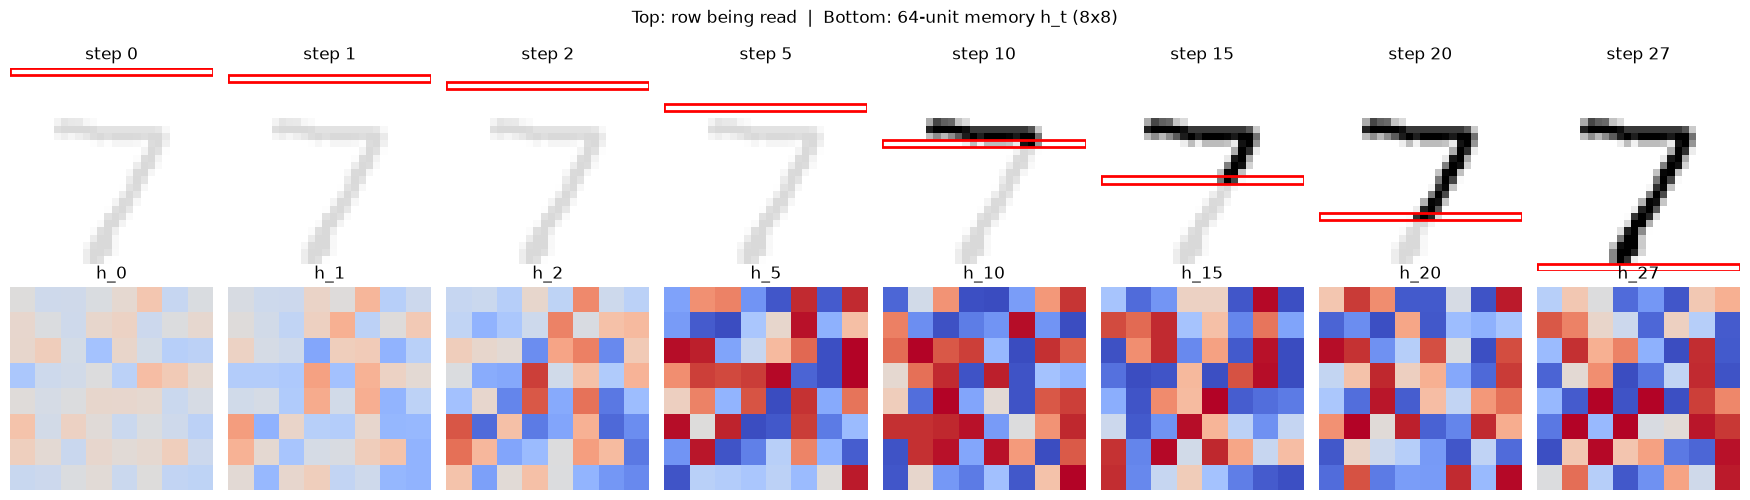

In [8]:
steps = [0, 1, 2, 5, 10, 15, 20, 27]
fig, axes = plt.subplots(2, len(steps), figsize=(2.2 * len(steps), 5))
for j, t in enumerate(steps):
    shown = IMG.copy(); shown[t + 1:, :] *= 0.15
    axes[0, j].imshow(shown, cmap="gray_r", vmin=0, vmax=1)
    axes[0, j].add_patch(plt.Rectangle((-0.5, t - 0.5), 28, 1, fill=False, ec="red", lw=2))
    axes[0, j].set_title(f"step {t}"); axes[0, j].axis("off")
    axes[1, j].imshow(H[t].reshape(8, 8), cmap="coolwarm", vmin=-1, vmax=1)
    axes[1, j].set_title(f"h_{t}"); axes[1, j].axis("off")
fig.suptitle("Top: row being read  |  Bottom: 64-unit memory h_t (8x8)", y=1.0)
plt.tight_layout(); plt.show()

## 8. 마무리: 마지막 메모만으로 분류한다는 것의 의미

`h_27` 하나에 앞의 모든 줄 정보가 압축돼 있습니다. 아래는 각 스텝의 `h_t`만 `fc`에 넣어 봤을 때,
**읽은 줄이 늘수록 정답 쪽 점수가 어떻게 변하는지** 보여줍니다. (학습한 모델에서는 아래쪽 줄을 읽을수록 확신이 커지는 경향이 보입니다. 학습 전 모델에서는 의미 없는 값이 나옵니다.)

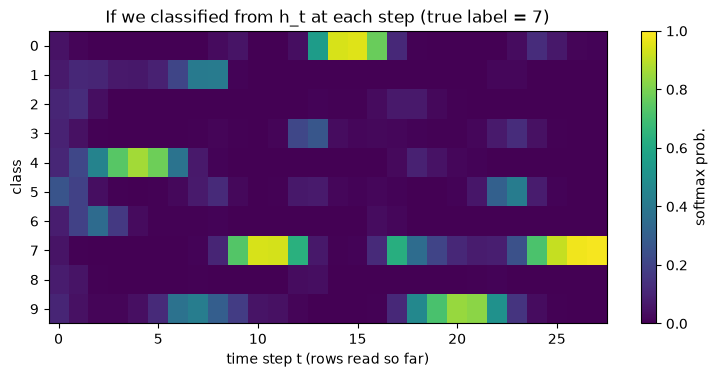

In [9]:
with torch.no_grad():
    per_step_logits = model.fc(outputs[0]).cpu().numpy()      # (28, 10)  각 h_t를 fc에 통과
probs = np.exp(per_step_logits - per_step_logits.max(1, keepdims=True))
probs /= probs.sum(1, keepdims=True)

plt.figure(figsize=(9, 3.8))
plt.imshow(probs.T, aspect="auto", cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="softmax prob.")
plt.xlabel("time step t (rows read so far)"); plt.ylabel("class"); plt.yticks(range(10))
plt.title(f"If we classified from h_t at each step (true label = {label})")
plt.show()